# Follow-up: stability, auxiliary features and nested specialists

The starting hybrid scored **0.912393 validation sample-wise F1**. The current best is **0.912393**. Requested target: strictly above 0.92735. These scores have not been measured on Kaggle.

This follow-up tested 49 stability/feature/score-combination configurations and 17 nested specialists. All 78 validation rows remain excluded from fitting. The final train-plus-validation refit remains deferred.

The full search is adaptive and the validation set has been consulted repeatedly. Fixed-candidate CV audits and small frozen validation batches reduce some leakage risks but do not make the entire model-selection process unbiased.

In [1]:
from pathlib import Path
import json,pandas as pd,numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
summary=json.loads((root/'experiments/phase22-23-summary.json').read_text())
summary

{'screened_configurations': 66,
 'phase22_screened': 49,
 'phase23_screened': 17,
 'validation_candidates': 3,
 'baseline_validation_f1': 0.9123931623931625,
 'current_validation_f1': 0.9123931623931625,
 'best_followup_validation_f1': 0.8952991452991452,
 'previous_baseline_retained': True,
 'baseline_additional_cv': 0.9037508846426042,
 'baseline_additional_cv_std': 0.003608647921863258,
 'additional_cv_seeds': [20261111, 20261112, 20261113],
 'validation_labels_used_for_training': 0,
 'final_train_plus_validation_refit_performed': False,
 'target_met': False}

## Why these experiments

The new tri-training component previously had no auxiliary-feature trials and only one bootstrap initialization. It also combined hard labels with the SVM, discarding confidence information. The earlier broad search did not test these exact combinations.

Training-only OOF errors identified Other as the largest remaining weakness: approximately 12.3 false positives and 8.3 false negatives per complete OOF pass, averaged over the original three split seeds. This motivated a dedicated Other classifier without selecting individual validation mistakes.

We used fixed ensembles of the first three or all five predetermined bootstrap seeds, never selecting the best seed. Feature blocks were added separately at two weights: eligibility criteria (word and character TF-IDF), diseases, drugs, ICD codes, drug targets/actions/pathways, molecular fingerprints/descriptors, year and field counts. Small changes to regularization, bandwidth, pseudo-label weight, confidence gates and preprocessing were also evaluated.

The score-combination variants align the original component thresholds before averaging. Their values are heuristic scores, not calibrated probabilities. The previous per-reason mask remained fixed during the feature and parameter screens.

In [2]:
screen=json.loads((root/'experiments/phase22-screen.json').read_text())
rows=[]
for r in screen:
 t=r['config']['tri']
 if r['bucket']=='features': rows.append(dict(feature=t['features'][0],weight=t['feature_weight'],ordinary_cv=r['ordinary'],weighted_robust_cv=r['robust']))
pd.DataFrame(rows).sort_values('weighted_robust_cv',ascending=False)

,feature,weight,ordinary_cv,weighted_robust_cv
7,drugs,0.40,0.910828,0.912196
17,fingerprint,0.40,0.910828,0.908012
5,diseases_cleaned,0.40,0.908705,0.906718
23,counts,0.40,0.904459,0.902618
9,icdcodes,0.40,0.904459,0.902432
1,criteria,0.40,0.900212,0.901090
15,drug_pathways,0.40,0.902335,0.900318
3,criteria_char,0.40,0.900212,0.900099
14,drug_pathways,0.15,0.906582,0.899391
11,drug_targets,0.40,0.900212,0.899170


## Nested specialists

Each outer training fold contains its own 15-fold grouped inner CV. The inner models generate ten score features: five from the SVM and five from tri-training. No row's label is fitted by the model that generates its inner OOF score features. Matching masked embedding duplicates of both inner and outer held-out groups are excluded.

Regularized logistic classifiers use these scores to predict Other alone, Recruitment and Other, or all five reasons. Other-only variants also test score interactions and conservative blending. A multinomial pattern model supplies a separate decoder that chooses the label set with maximum expected sample-wise F1. Earlier calibration experiments used only the old SVM; these experiments use both current components.

The specialists' complexity settings are selected from outer training CV. This is nested feature generation, not an independent nested rerun of the entire historical hyperparameter search.

In [3]:
rep22=json.loads((root/'experiments/phase22-repeat-results.json').read_text())
rep23=json.loads((root/'experiments/phase23-repeat-results.json').read_text())
rows=[dict(batch=batch,variant=r['bucket'],mean_cv=r['ordinary_cv'],split_std=r['cv_std'],robust_cv=r['robust_cv']) for batch,rs in [('22',rep22),('23',rep23)] for r in rs]
pd.DataFrame(rows)

,batch,variant,mean_cv,split_std,robust_cv
0,22,control,0.903751,0.003609,0.893313
1,22,bootstrap,0.900212,0.009652,0.888686
2,22,parameters,0.907856,0.007929,0.899215
3,22,features,0.902335,0.006250,0.890651
4,22,soft,0.920736,0.009857,0.912558
5,23,all,0.910828,0.007944,0.896356
6,23,other,0.903043,0.014744,0.890805


## Validation and interpretation

Candidate configurations and decision rules were written to frozen JSON files before loading validation labels. Only finalists meeting the prespecified training-CV screen were evaluated on validation. All results, including failures to improve, appear below.

The control's scores on the additional split seeds differ from its earlier three-seed CV. That variability is useful evidence of the uncertainty created by just 157 gold rows; do not compare scores from different split sets as if they were paired measurements.

In [4]:
results=sum([json.loads((root/f'experiments/phase{n}-validation-results.json').read_text()) for n in [22,23]],[])
validation=pd.DataFrame([dict(candidate=r['name'],cv=r['ordinary_cv'],validation_f1=r['validation']['sample_f1'],macro_f1=r['validation']['macro_f1']) for r in results])
validation

,candidate,cv,validation_f1,macro_f1
0,phase22_soft,0.920736,0.880342,0.743470
1,phase22_features,0.902335,0.895299,0.769412
2,phase23_all,0.910828,0.871795,0.698222


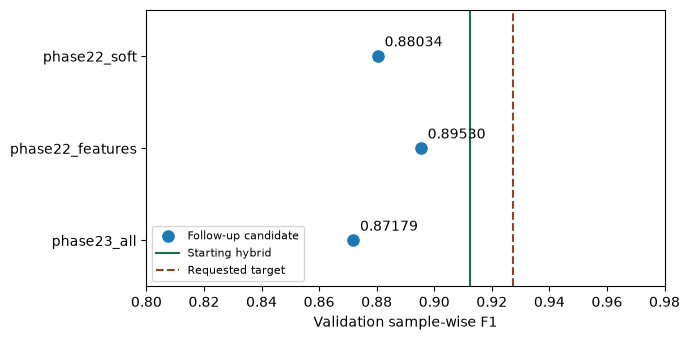

In [5]:
fig,ax=plt.subplots(figsize=(7,3.5))
y=np.arange(len(validation))
ax.scatter(validation.validation_f1,y,s=65,label='Follow-up candidate')
ax.axvline(summary['baseline_validation_f1'],color='#197144',label='Starting hybrid')
ax.axvline(.92735,color='#9b3e27',linestyle='--',label='Requested target')
for i,s in enumerate(validation.validation_f1):ax.annotate(f'{s:.5f}',(s,i),xytext=(5,7),textcoords='offset points')
ax.set(yticks=y,yticklabels=validation.candidate,xlim=(.8,.98),xlabel='Validation sample-wise F1')
ax.margins(y=.25);ax.invert_yaxis();ax.legend(loc='lower left',fontsize=8)
fig.tight_layout();fig.savefig(root/'figures/current_phase22_23_comparison.png',dpi=180)
plt.show()

## Reproduction and integrity

Protocols, exact configurations, OOF scores and frozen validation batches are under `experiments/phase22*` and `experiments/phase23*`. All source is embedded in notebook 04. The phase22 core was checked against phase21 with matching defaults. The nested specialist passed an uncached held-out-label perturbation check; caches were cleared to prevent them from masking leakage. Raw inputs and gold labels remain unchanged.

Method references: [bootstrap aggregation](https://statistics.berkeley.edu/tech-reports/421), [out-of-fold stacking](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html), and [exact F-measure decoding](https://proceedings.neurips.cc/paper/2011/hash/71ad16ad2c4d81f348082ff6c4b20768-Abstract.html). No external trial records or labels were retrieved.

In [6]:
json.loads((root/'experiments/phase23-integrity-checks.json').read_text())

{'nested_heldout_label_invariance': True,
 'caches_cleared_before_perturbation': True,
 'query_batch_invariance': True,
 'binary_nonempty': True,
 'max_difference': 0.0,
 'heldout_rows': 31,
 'validation_used_for_training': False,
 'source_sha256': {'phase22.py': 'ce837c5e83daca1a05fe6df25842e6b4336917a8e27514e029bfe9d0e5c6ab1b',
  'phase23.py': '634494f719756ed4273552a53dc93f95ec76f78048d72c5e34365cb5aec710d3'}}